# Methodology Script: DJIA Partial-Correlation PMFG Network and Portfolio

Follows the methodology slide in this order:

1. Market Mode Removal -> 2. Partial Correlation -> 3. Tracy-Widom Test
4. Distance Matrix -> 5. Network Filtering (PMFG) -> 6. Cluster Detection (Louvain)
7. ARI Bootstrap -> 8. Centrality Measures -> 9. Portfolio Construction

## Decisions fixed by the author (not to be changed)
* **No denoising.** QIS is NOT used anywhere (main analysis or bootstrap).
* **No forecasting.** Everything is in-sample and descriptive. There is no rolling or out-of-sample test.
* **Stock selection:** the stock with the LOWEST eigenvector centrality in each community.
* **Bootstrap size:** 200 replications.

## Contradictions in the old notebook that this script removes
| Old notebook | This script |
|---|---|
| QIS applied in main run and bootstrap | Removed (no denoising) |
| Markdown said "highest" centrality, code used idxmin | Lowest everywhere (code and text) |
| Weights `1 - c/max` in rolling test vs `c/sum(c)` in main | One rule only: `w_k = nu_k / sum(nu_j)` |
| Regression on raw log-returns vs chapter's standardised Z | Regression on standardised returns Z (switch below) |
| python-louvain in main/bootstrap, NetworkX Louvain later (overwrote `partition`) | python-louvain only, `partition` defined once |
| NVDA dropped from `weekly_log_returns` in later cells | All 30 stocks kept throughout |
| Bootstrap 10,000 in code vs 200 in notes | 200 in code and notes |
| Rolling out-of-sample test, MPT benchmark | Removed (not part of the methodology slide) |
| Hard-coded result numbers | Everything computed |

## Reproducibility
* Fixed seed 42 for NumPy, `random`, Louvain and the bootstrap RNG.
* Prices are frozen to a CSV snapshot on first run and re-loaded on later runs (so Yahoo revisions cannot change your results).
* The bootstrap cache is keyed to the data fingerprint, seed, size AND a pipeline tag, so a cache from the old (QIS) version can never be re-used by mistake.

In [23]:
%pip install -q yfinance python-louvain TracyWidom plotly seaborn scikit-learn networkx scipy

Note: you may need to restart the kernel to use updated packages.


In [24]:
import os, sys, random, hashlib, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import community.community_louvain as community_louvain   # python-louvain (the ONLY Louvain used)
from scipy.linalg import pinv
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from TracyWidom import TracyWidom

warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------- configuration ----------------
SEED = 42
N_BOOTSTRAP = int(os.environ.get("N_BOOTSTRAP", 10000))   # 200 as specified
DATA_DIR = os.environ.get("DATA_DIR", ".")               # where the frozen snapshots live
OUT_DIR = os.environ.get("OUT_DIR", "outputs")           # tables and figures are saved here
REGRESS_ON_STANDARDISED = True    # chapter 4.5.3: regress standardised Z on PC1 (False = raw log-returns)
PIPELINE_TAG = "v2|no_qis|std_regression|pylouvain|lowest_centrality"

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED)
random.seed(SEED)

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| networkx", nx.__version__, "| python-louvain", getattr(community_louvain, "__version__", "n/a"))
print(f"N_BOOTSTRAP = {N_BOOTSTRAP}, SEED = {SEED}, regress on standardised = {REGRESS_ON_STANDARDISED}")

Python 3.13.9 | numpy 2.3.5 | pandas 2.3.3 | networkx 3.5 | python-louvain n/a
N_BOOTSTRAP = 10000, SEED = 42, regress on standardised = True


## 1. Data acquisition (weekly, Friday closes)
* Daily adjusted closes (`auto_adjust=True`, so dividends and splits are included) are converted to weekly Friday closes.
* The first successful run saves a snapshot CSV; later runs load it. Delete the CSV if you ever want to re-download.
* The DJIA index (`^DJI`) is stored the same way for the benchmark comparison.
* Note: `^DJI` is a price index (no dividends) while the stock prices are dividend-adjusted. Mention this when comparing.

In [25]:
djia_tickers = [
    "AAPL", "AMGN", "AMZN", "AXP", "BA", "CAT", "CRM", "CSCO", "CVX", "DIS",
    "GS", "HD", "HON", "IBM", "JNJ", "JPM", "KO", "MCD", "MMM", "MRK",
    "MSFT", "NKE", "NVDA", "PG", "SHW", "TRV", "UNH", "V", "VZ", "WMT",
]

DATA_FILE = os.path.join(DATA_DIR, "weekly_prices_frozen_2015_2025.csv")
DJIA_FILE = os.path.join(DATA_DIR, "djia_weekly_frozen_2015_2025.csv")

if os.path.exists(DATA_FILE):
    weekly_prices = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[djia_tickers]
    print("Loaded frozen weekly-price snapshot:", DATA_FILE)
else:
    import yfinance as yf
    df = yf.download(tickers=djia_tickers, start="2015-01-01", end="2026-01-01",
                     interval="1d", auto_adjust=True, group_by="ticker", threads=True)
    close_prices = df.xs("Close", axis=1, level=1)
    weekly_prices = close_prices.resample("W-FRI").last().loc["2015-01-01":"2025-12-31"]
    weekly_prices = weekly_prices[djia_tickers].dropna(axis=1, how="any")
    if weekly_prices.shape != (574, 30):
        raise ValueError(f"Unexpected weekly price shape {weekly_prices.shape}; snapshot NOT created.")
    weekly_prices.to_csv(DATA_FILE)
    print("Created frozen weekly-price snapshot:", DATA_FILE)

if os.path.exists(DJIA_FILE):
    djia_weekly = pd.read_csv(DJIA_FILE, index_col=0, parse_dates=True).iloc[:, 0]
else:
    import yfinance as yf
    dji = yf.download("^DJI", start="2015-01-01", end="2026-01-01", interval="1d",
                      auto_adjust=True, progress=False)["Close"]
    if isinstance(dji, pd.DataFrame):
        dji = dji.iloc[:, 0]
    djia_weekly = dji.resample("W-FRI").last().loc["2015-01-01":"2025-12-31"]
    djia_weekly.rename("DJIA").to_csv(DJIA_FILE)
    print("Created frozen DJIA snapshot:", DJIA_FILE)

assert weekly_prices.shape == (574, 30), weekly_prices.shape
assert list(weekly_prices.columns) == djia_tickers
assert weekly_prices.index.max() <= pd.Timestamp("2025-12-31")
assert weekly_prices.isna().sum().sum() == 0

# Fingerprint of the exact input (used to key the bootstrap cache)
data_hash = hashlib.sha256(
    weekly_prices.to_csv(date_format="%Y-%m-%dT%H:%M:%S").encode()).hexdigest()
print("Range:", weekly_prices.index.min().date(), "to", weekly_prices.index.max().date(),
      "| stocks:", weekly_prices.shape[1], "| SHA256:", data_hash[:16])

Loaded frozen weekly-price snapshot: .\weekly_prices_frozen_2015_2025.csv
Range: 2015-01-02 to 2025-12-26 | stocks: 30 | SHA256: 2b3168a452d9a6de


### Weekly log-returns
`r_t = ln(P_t / P_{t-1})`. 574 weekly prices give 573 weekly returns for each of the 30 stocks.
**All 30 stocks stay in this table for the whole script (NVDA is never dropped).**

In [26]:
weekly_log_returns = np.log(weekly_prices / weekly_prices.shift(1)).dropna(how="any")
assert weekly_log_returns.shape == (573, 30), weekly_log_returns.shape
print("Weekly observations:", len(weekly_log_returns), "| stocks:", weekly_log_returns.shape[1])

Weekly observations: 573 | stocks: 30


      variance  std_dev  annualised_vol
JNJ     0.0006   0.0236          0.1701
PG      0.0006   0.0239          0.1725
KO      0.0007   0.0258          0.1858
MCD     0.0007   0.0264          0.1903
VZ      0.0007   0.0269          0.1942
WMT     0.0008   0.0291          0.2099
V       0.0009   0.0299          0.2159
MRK     0.0009   0.0306          0.2203
TRV     0.0010   0.0311          0.2242
HON     0.0011   0.0325          0.2345
CSCO    0.0011   0.0326          0.2353
MSFT    0.0011   0.0327          0.2358
IBM     0.0011   0.0337          0.2431
MMM     0.0012   0.0343          0.2471
AMGN    0.0012   0.0344          0.2482
SHW     0.0012   0.0351          0.2531
HD      0.0012   0.0353          0.2544
JPM     0.0013   0.0367          0.2646
DIS     0.0014   0.0370          0.2670
AAPL    0.0015   0.0383          0.2759
CVX     0.0015   0.0391          0.2821
GS      0.0017   0.0411          0.2965
CAT     0.0017   0.0415          0.2992
AMZN    0.0018   0.0419          0.3023


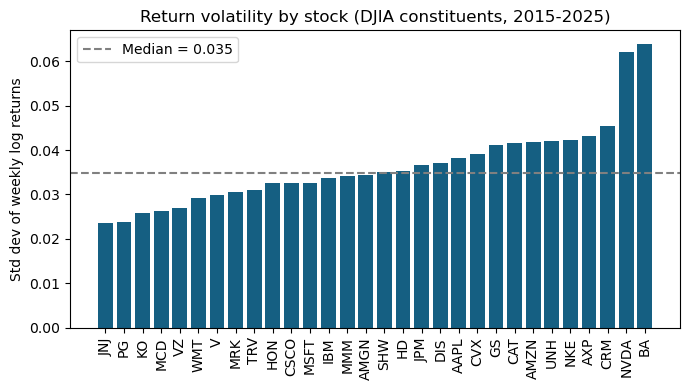

In [46]:
from scipy import stats

returns = weekly_log_returns          # 573 x 30, already computed above

# Per-stock variance / volatility of weekly log returns
var_table = pd.DataFrame({
    "variance": returns.var(ddof=1),
    "std_dev": returns.std(ddof=1),
}).sort_values("std_dev")
var_table["annualised_vol"] = var_table["std_dev"] * np.sqrt(52)
var_table.to_csv(os.path.join(OUT_DIR, "appendix_return_variance.csv"), float_format="%.6f")
print(var_table.round(4).to_string())

sd = var_table["std_dev"]
print(f"\nWeekly std dev: min {sd.min():.4f} ({sd.idxmin()}), max {sd.max():.4f} ({sd.idxmax()}), "
      f"median {sd.median():.4f}, max/min = {sd.max()/sd.min():.2f}")
print(f"Variance ratio (max/min) = {var_table['variance'].max()/var_table['variance'].min():.2f}")

# Tests of equal variances (null: all 30 stocks have the same variance)
cols = [returns[c].values for c in returns.columns]
W, p_lev = stats.levene(*cols, center="median")
T, p_bar = stats.bartlett(*cols)
print(f"Levene (median): W = {W:.3f}, p = {p_lev:.3g}")
print(f"Bartlett       : T = {T:.3f}, p = {p_bar:.3g}")

# Figure
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(var_table.index, var_table["std_dev"], color="#155F82")
ax.axhline(sd.median(), color="grey", ls="--", label=f"Median = {sd.median():.3f}")
ax.set_ylabel("Std dev of weekly log returns")
ax.set_title("Return volatility by stock (DJIA constituents, 2015-2025)")
plt.xticks(rotation=90); ax.legend(); fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "appendix_return_volatility.png"), dpi=200)
plt.show()

---
# Step 1. Market Mode Removal
1. Standardise each stock's weekly returns (z-score).
2. PCA on the standardised returns; PC1 = market mode.
3. Check the PC1 loadings mostly share one sign (market-mode criterion).
4. Regress each stock on the PC1 scores (OLS with intercept); keep the residuals.

The same function `remove_market_mode()` is used in the main run AND in every bootstrap replicate, so they cannot drift apart.
The OLS is done with `numpy.linalg.lstsq`. It gives identical residuals to `statsmodels.OLS` and is faster for the bootstrap.
The sign of a PCA component is arbitrary, but residuals do not depend on it.

In [27]:
def remove_market_mode(returns, details=False):
    """Standardise -> PCA(1) -> regress each stock on PC1 -> residuals."""
    scaler = StandardScaler()
    Z = pd.DataFrame(scaler.fit_transform(returns), index=returns.index, columns=returns.columns)

    pca = PCA(n_components=1, svd_solver="full")
    pc1 = pca.fit_transform(Z.values).ravel()

    Xreg = np.column_stack([np.ones(len(pc1)), pc1])           # intercept + PC1
    Y = Z.values if REGRESS_ON_STANDARDISED else returns.values
    beta, *_ = np.linalg.lstsq(Xreg, Y, rcond=None)             # (2 x N): alpha_i, beta_i
    resid = Y - Xreg @ beta
    residuals = pd.DataFrame(resid, index=returns.index, columns=returns.columns)

    if not details:
        return residuals
    ss_res = (resid ** 2).sum(axis=0)
    ss_tot = ((Y - Y.mean(axis=0)) ** 2).sum(axis=0)
    info = {
        "pc1": pd.Series(pc1, index=returns.index, name="PC1"),
        "loadings": pd.Series(pca.components_[0], index=returns.columns, name="PC1_loading"),
        "explained_variance_ratio": float(pca.explained_variance_ratio_[0]),
        "alpha": pd.Series(beta[0], index=returns.columns),
        "beta": pd.Series(beta[1], index=returns.columns),
        "r2": pd.Series(1 - ss_res / ss_tot, index=returns.columns, name="R2_on_PC1"),
    }
    return residuals, info

residual_returns, mm = remove_market_mode(weekly_log_returns, details=True)
market_mode, loadings = mm["pc1"], mm["loadings"]

n_pos, n_neg = int((loadings > 0).sum()), int((loadings < 0).sum())
same_sign_fraction = max(n_pos, n_neg) / len(loadings)
print(f"PC1 explains {mm['explained_variance_ratio']:.1%} of total variance")
print(f"Positive loadings: {n_pos}/30 | negative: {n_neg}/30 | same-sign fraction: {same_sign_fraction:.3f}")
print("PC1 is consistent with the market-mode criterion." if same_sign_fraction > 0.80
      else "PC1 does NOT meet the >80% same-sign criterion; interpret with caution.")
print("Mean R^2 of stocks on PC1:", round(mm["r2"].mean(), 3))

PC1 explains 41.5% of total variance
Positive loadings: 30/30 | negative: 0/30 | same-sign fraction: 1.000
PC1 is consistent with the market-mode criterion.
Mean R^2 of stocks on PC1: 0.415


### Market-mode validation plot
PC1 is oriented so that its loadings are mostly positive (display only). We compare its cumulative movement with the cumulative
equal-weight average return and report their correlation.

Correlation (PC1 vs equal-weight average return): 0.997


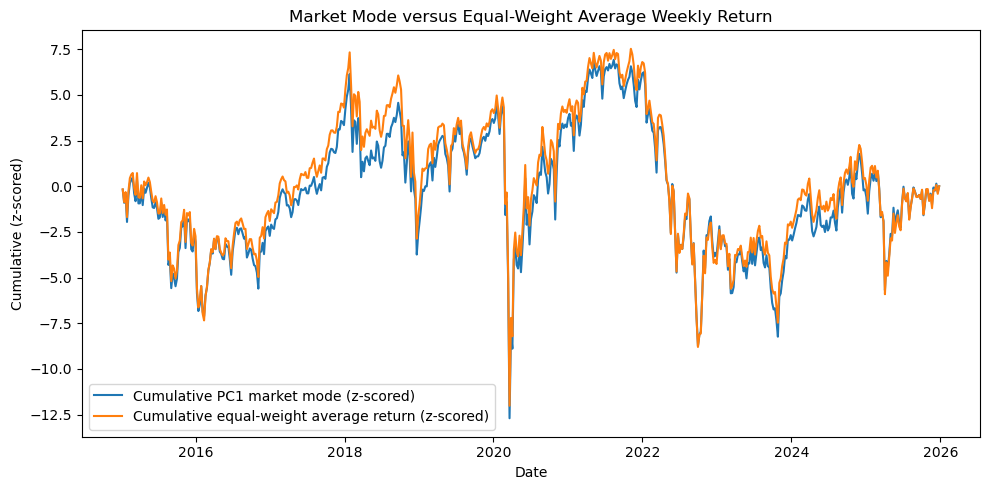

In [28]:
pc1_plot = market_mode if loadings.mean() >= 0 else -market_mode
ew_log_series = weekly_log_returns.mean(axis=1)
print("Correlation (PC1 vs equal-weight average return):", round(np.corrcoef(pc1_plot, ew_log_series)[0, 1], 3))

# Both series are z-scored for display because PC1 is in standardised units and returns are in log units.
zs = lambda s: (s - s.mean()) / s.std()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(zs(pc1_plot).cumsum(), label="Cumulative PC1 market mode (z-scored)")
ax.plot(zs(ew_log_series).cumsum(), label="Cumulative equal-weight average return (z-scored)")
ax.set_title("Market Mode versus Equal-Weight Average Weekly Return")
ax.set_xlabel("Date"); ax.set_ylabel("Cumulative (z-scored)"); ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "fig_market_mode.png"), dpi=150); plt.show()

---
# Step 2. Partial Correlation Calculation (no denoising)
`rho_ij.others = -Theta_ij / sqrt(Theta_ii * Theta_jj)` with `Theta = Sigma^-1`, using the covariance of the market-mode-adjusted residuals.

**Important note.** Because the residuals are what is left after regressing on PC1, they satisfy one exact linear constraint, so the
residual covariance has rank N-1 and is singular. Therefore `pinv` (Moore-Penrose pseudo-inverse) is used. The cell prints the rank
and smallest eigenvalues so you can quote them. The partial correlations are scale-free, so it does not matter that the
residuals have different variances.

Residual covariance rank: 29 of 30
Smallest 3 eigenvalues: [0.         0.12718748 0.186146  ]


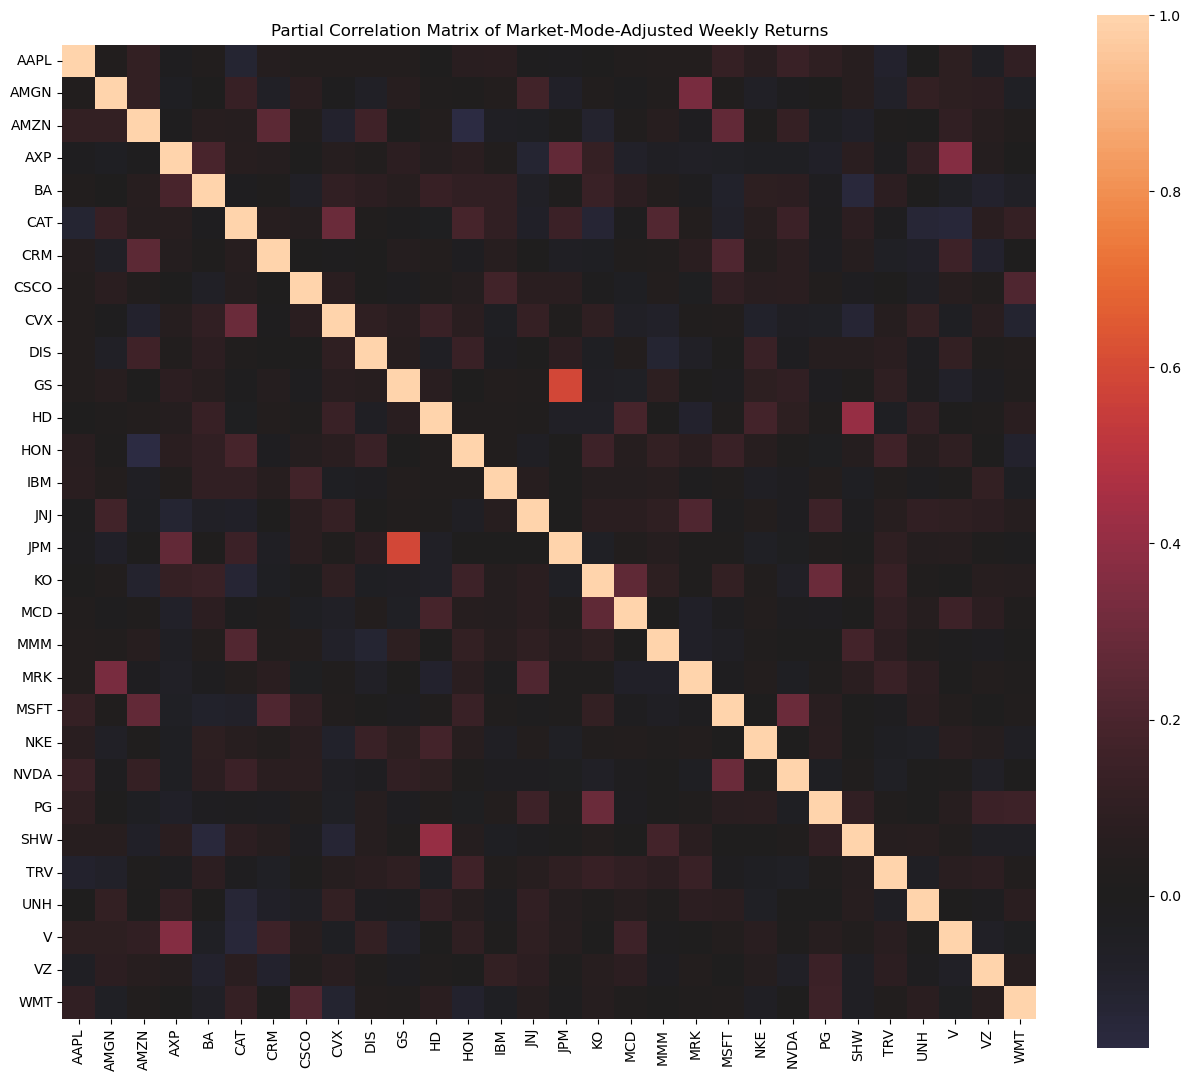

In [29]:
def partial_corr_from_cov(cov):
    precision = pinv(np.asarray(cov, dtype=float))
    d = np.maximum(np.diag(precision), 1e-12)
    pc = -precision / np.outer(np.sqrt(d), np.sqrt(d))
    np.fill_diagonal(pc, 1.0)
    return np.clip(pc, -1.0, 1.0)

cov_residual = residual_returns.cov()
eig_cov = np.linalg.eigvalsh(cov_residual.values)
print("Residual covariance rank:", np.linalg.matrix_rank(cov_residual.values), "of", cov_residual.shape[0])
print("Smallest 3 eigenvalues:", np.round(eig_cov[:3], 12))

partial_corr_df = pd.DataFrame(partial_corr_from_cov(cov_residual.values),
                               index=residual_returns.columns, columns=residual_returns.columns)
partial_corr_df.to_csv(os.path.join(OUT_DIR, "partial_correlation_matrix.csv"))

fig = plt.figure(figsize=(13, 11))
sns.heatmap(partial_corr_df, center=0, square=True, xticklabels=True, yticklabels=True)
plt.title("Partial Correlation Matrix of Market-Mode-Adjusted Weekly Returns")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_partial_corr_heatmap.png"), dpi=150); plt.show()

---
# Step 3. Tracy-Widom test (Random Matrix Theory diagnostic)
Applied to the correlation matrix of the market-mode-adjusted residuals.
* H0: the largest residual eigenvalue is consistent with random-matrix noise.
* Marchenko-Pastur bounds are also reported: `lambda+- = 1 + 1/Q +- 2 sqrt(1/Q)`, with `Q = T/N`.
* This is a **diagnostic only**: it does not change the residuals, network or portfolio.

T = 573, N = 30, Q = 19.100
Marchenko-Pastur bounds: [0.595, 1.510]
Eigenvalues above upper bound: 4 | largest = 3.508
TW statistic = 64.202, p-value = 0.0000
Reject H0 at 5%: largest eigenvalue exceeds the random-matrix prediction.


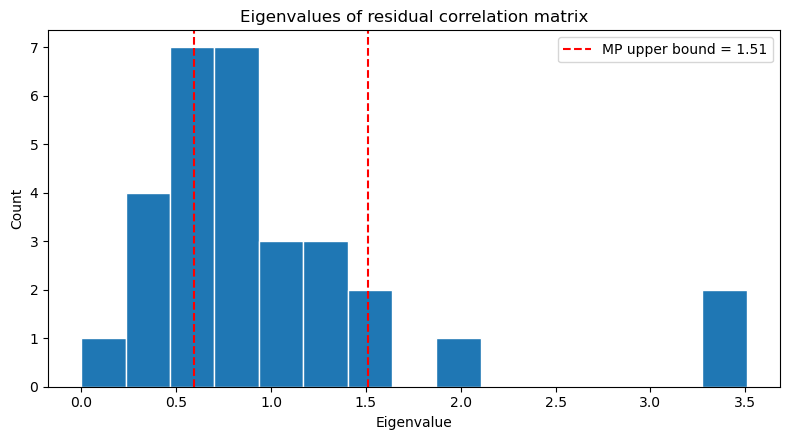

In [30]:
X = (residual_returns - residual_returns.mean()) / residual_returns.std(ddof=1)
T, N = X.shape
corr = np.corrcoef(X.values, rowvar=False)
corr = (corr + corr.T) / 2
eigvals = np.linalg.eigvalsh(corr)
lambda_max = eigvals[-1]

# Marchenko-Pastur bounds
Q = T / N
lam_minus = 1 + 1 / Q - 2 * np.sqrt(1 / Q)
lam_plus = 1 + 1 / Q + 2 * np.sqrt(1 / Q)
print(f"T = {T}, N = {N}, Q = {Q:.3f}")
print(f"Marchenko-Pastur bounds: [{lam_minus:.3f}, {lam_plus:.3f}]")
print(f"Eigenvalues above upper bound: {(eigvals > lam_plus).sum()} | largest = {lambda_max:.3f}")

# Tracy-Widom (Johnstone-type centring and scaling, as in the original notebook)
n, p = T, N
mu = ((np.sqrt(n - 0.5) + np.sqrt(p - 0.5)) ** 2) / n
sigma = ((np.sqrt(n - 0.5) + np.sqrt(p - 0.5)) *
         (1 / np.sqrt(n - 0.5) + 1 / np.sqrt(p - 0.5)) ** (1 / 3)) / n
tw_statistic = (lambda_max - mu) / sigma
p_value = 1 - TracyWidom(beta=1).cdf(tw_statistic)
print(f"TW statistic = {tw_statistic:.3f}, p-value = {p_value:.4f}")
print("Reject H0 at 5%: largest eigenvalue exceeds the random-matrix prediction." if p_value < 0.05
      else "Fail to reject H0 at 5%: largest eigenvalue is consistent with random-matrix noise.")

fig = plt.figure(figsize=(8, 4.5))
plt.hist(eigvals, bins=15, edgecolor="white")
plt.axvline(lam_plus, color="red", ls="--", label=f"MP upper bound = {lam_plus:.2f}")
plt.axvline(lam_minus, color="red", ls="--")
plt.xlabel("Eigenvalue"); plt.ylabel("Count"); plt.title("Eigenvalues of residual correlation matrix")
plt.legend(); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_rmt_eigenvalues.png"), dpi=150); plt.show()

---
# Step 4. Distance Matrix
`d_ij = sqrt(2 (1 - rho_ij))`, with `rho_ij` the partial correlation. The diagonal is 0.

In [31]:
def make_distance_df(partial_corr):
    pc = np.asarray(partial_corr, dtype=float)
    d = np.sqrt(np.maximum(0.0, 2.0 * (1.0 - pc)))
    np.fill_diagonal(d, 0.0)
    return d

distance_matrix = pd.DataFrame(make_distance_df(partial_corr_df.values),
                               index=partial_corr_df.index, columns=partial_corr_df.columns)
distance_matrix.to_csv(os.path.join(OUT_DIR, "distance_matrix.csv"))

### Raw (unfiltered) network
Complete graph on 30 nodes (435 edges), drawn before filtering to show why filtering is needed.

**Edge weights.** The graph stores both `distance` and `weight = 1/(d + 1e-12)`. Louvain and eigenvector centrality need a
*similarity* (bigger = stronger), so they use `weight`. The PMFG itself is built from `distance`.

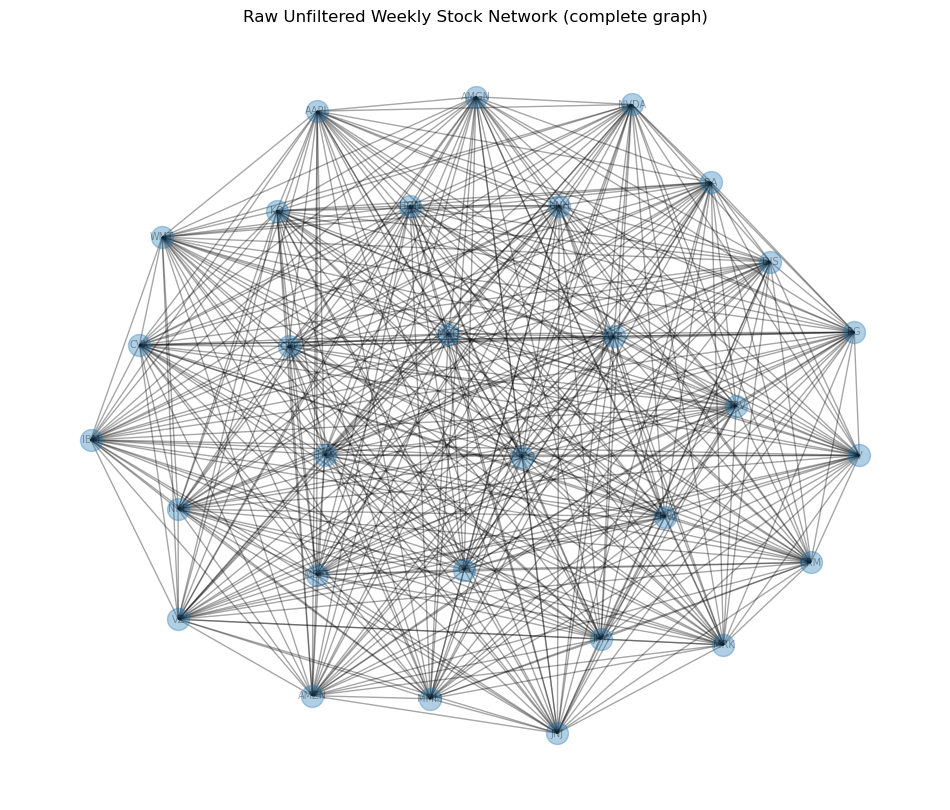

In [32]:
def build_complete_graph(dist_df):
    G = nx.Graph(); t = list(dist_df.columns); G.add_nodes_from(t)
    for i in range(len(t)):
        for j in range(i + 1, len(t)):
            d = float(dist_df.iloc[i, j])
            G.add_edge(t[i], t[j], distance=d, weight=1 / (d + 1e-12))
    return G

G_raw = build_complete_graph(distance_matrix)
pos_raw = nx.spring_layout(G_raw, seed=SEED)
fig = plt.figure(figsize=(12, 10))
nx.draw_networkx(G_raw, pos=pos_raw, node_size=250, font_size=7, alpha=0.35)
plt.title("Raw Unfiltered Weekly Stock Network (complete graph)"); plt.axis("off")
plt.savefig(os.path.join(OUT_DIR, "fig_raw_network.png"), dpi=150); plt.show()

---
# Step 5. Network Filtering: Planar Maximally Filtered Graph (PMFG)
Edges are considered from smallest distance (strongest) to largest, and an edge is kept only if the graph stays planar,
until `3(N-2) = 84` edges are reached. Ties are broken by ticker name, so the result is deterministic.

PMFG nodes: 30 | edges: 84 | theoretical max: 84 | planar: True


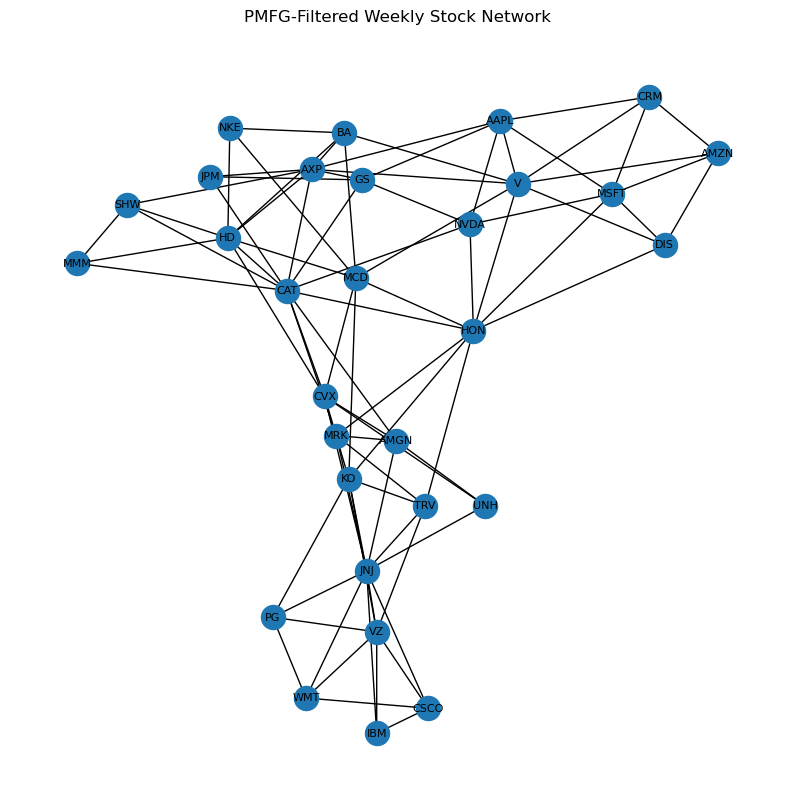

In [33]:
def build_pmfg(dist_df):
    t = list(dist_df.columns)
    cand = sorted(((float(dist_df.iloc[i, j]), t[i], t[j])
                   for i in range(len(t)) for j in range(i + 1, len(t))),
                  key=lambda x: (x[0], x[1], x[2]))
    G = nx.Graph(); G.add_nodes_from(t)
    max_edges = 3 * (len(t) - 2)
    for d, u, v in cand:
        if G.number_of_edges() >= max_edges:
            break
        G.add_edge(u, v, distance=d, weight=1 / (d + 1e-12))
        if not nx.check_planarity(G)[0]:
            G.remove_edge(u, v)
    return G

G_pmfg = build_pmfg(distance_matrix)
assert G_pmfg.number_of_nodes() == 30 and G_pmfg.number_of_edges() == 84
assert nx.check_planarity(G_pmfg)[0]
print("PMFG nodes:", G_pmfg.number_of_nodes(), "| edges:", G_pmfg.number_of_edges(),
      "| theoretical max:", 3 * (30 - 2), "| planar: True")

pos_pmfg = nx.spring_layout(G_pmfg, seed=SEED)
fig = plt.figure(figsize=(10, 10))
nx.draw_networkx(G_pmfg, pos=pos_pmfg, node_size=300, font_size=8)
plt.title("PMFG-Filtered Weekly Stock Network"); plt.axis("off")
plt.savefig(os.path.join(OUT_DIR, "fig_pmfg.png"), dpi=150); plt.show()

---
# Step 6. Cluster Detection (Louvain)
python-louvain `best_partition` on the PMFG with similarity weights and `random_state=42`.
`partition` is defined **once, here**, and is never overwritten. The ARI reference, Sankey, centrality and selection all use it.

Number of Louvain communities: 3
  Community 0: ['AAPL', 'AMZN', 'CRM', 'DIS', 'HON', 'MSFT', 'NVDA', 'V']
  Community 1: ['AXP', 'BA', 'CAT', 'GS', 'HD', 'JPM', 'MCD', 'MMM', 'NKE', 'SHW']
  Community 2: ['AMGN', 'CSCO', 'CVX', 'IBM', 'JNJ', 'KO', 'MRK', 'PG', 'TRV', 'UNH', 'VZ', 'WMT']


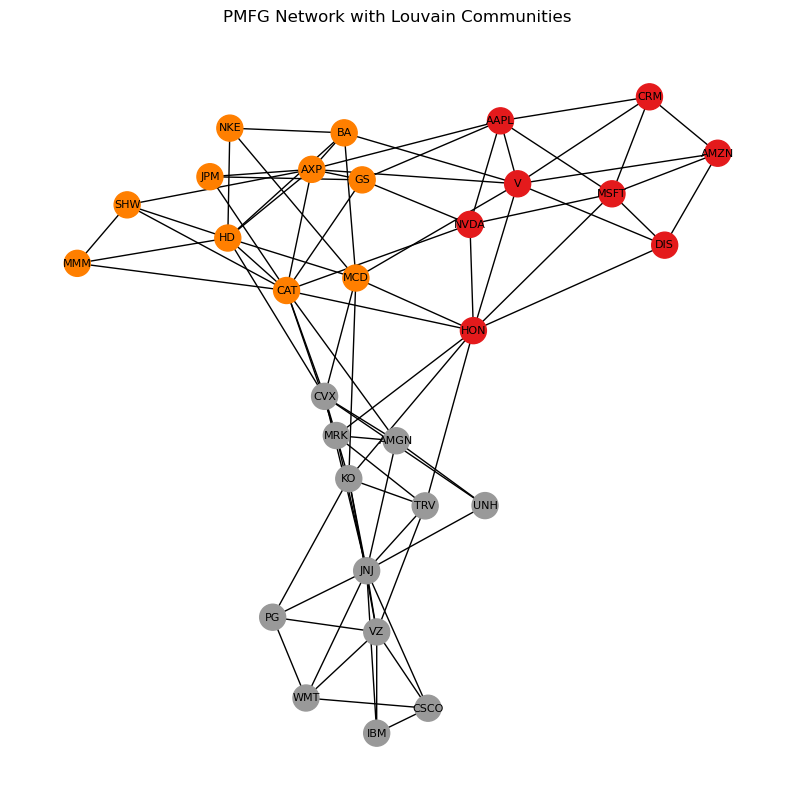

In [34]:
def detect_communities(G, seed):
    return community_louvain.best_partition(G, weight="weight", random_state=seed)

partition = detect_communities(G_pmfg, SEED)
n_communities = len(set(partition.values()))
print("Number of Louvain communities:", n_communities)
for c in sorted(set(partition.values())):
    print(f"  Community {c}: {sorted(k for k, v in partition.items() if v == c)}")

fig = plt.figure(figsize=(10, 10))
nx.draw_networkx(G_pmfg, pos=pos_pmfg, node_size=350, node_color=[partition[n] for n in G_pmfg.nodes()],
                 cmap=plt.cm.Set1, font_size=8)
plt.title("PMFG Network with Louvain Communities"); plt.axis("off")
plt.savefig(os.path.join(OUT_DIR, "fig_pmfg_communities.png"), dpi=150); plt.show()

### ICB Industry classification and Sankey diagram (ICB Industry -> Community -> Stock)
The ICB Industry mapping is kept separate from the return data. The Sankey is saved as an interactive HTML file
(no extra image-export package needed; use the camera icon in the plot for a PNG).

In [35]:
icb_industry_map = {
    "AAPL": "Technology", "AMGN": "Health Care", "AMZN": "Consumer Discretionary", "AXP": "Financials",
    "BA": "Industrials", "CAT": "Industrials", "CRM": "Technology", "CSCO": "Telecommunications",
    "CVX": "Energy", "DIS": "Consumer Discretionary", "GS": "Financials", "HD": "Consumer Discretionary",
    "HON": "Industrials", "IBM": "Technology", "JNJ": "Health Care", "JPM": "Financials",
    "KO": "Consumer Staples", "MCD": "Consumer Discretionary", "MMM": "Industrials", "MRK": "Health Care",
    "MSFT": "Technology", "NKE": "Consumer Discretionary", "NVDA": "Technology", "PG": "Consumer Staples",
    "SHW": "Basic Materials", "TRV": "Financials", "UNH": "Health Care", "V": "Industrials",
    "VZ": "Telecommunications", "WMT": "Consumer Staples",
}
assert set(icb_industry_map) == set(djia_tickers), "ICB mapping must cover exactly the 30 stocks"

sankey_df = pd.DataFrame({"Stock": djia_tickers,
                          "Community": [partition[t] for t in djia_tickers],
                          "ICB Industry": [icb_industry_map[t] for t in djia_tickers]})
sankey_df.sort_values(["Community", "ICB Industry", "Stock"]).to_csv(
    os.path.join(OUT_DIR, "community_vs_icb.csv"), index=False)
print(pd.crosstab(sankey_df["Community"], sankey_df["ICB Industry"]))

import plotly.graph_objects as go
sectors = sorted(sankey_df["ICB Industry"].unique())
comms = sorted(sankey_df["Community"].unique())
stocks_sorted = sorted(sankey_df["Stock"].unique())
labels = ([f"ICB: {s}" for s in sectors] + [f"Community {c}" for c in comms] + [f"{s}" for s in stocks_sorted])
idx = {l: i for i, l in enumerate(labels)}
src, tgt, val = [], [], []
for (s, c), cnt in sankey_df.groupby(["ICB Industry", "Community"]).size().items():
    src.append(idx[f"ICB: {s}"]); tgt.append(idx[f"Community {c}"]); val.append(int(cnt))
for _, r in sankey_df.iterrows():
    src.append(idx[f"Community {r['Community']}"]); tgt.append(idx[r["Stock"]]); val.append(1)
sk = go.Figure(go.Sankey(arrangement="snap", node=dict(pad=15, thickness=20, label=labels),
                         link=dict(source=src, target=tgt, value=val)))
sk.update_layout(title="Sankey: ICB Industry -> Louvain Community -> Stock", font_size=11, width=1200, height=800)
sk.write_html(os.path.join(OUT_DIR, "sankey_icb_community_stock.html"))
try:
    sk.show()
except Exception as e:   # e.g. no display when run as a plain script; the HTML file is already saved
    print('Sankey not displayed inline (saved as HTML instead):', type(e).__name__)

ICB Industry  Basic Materials  Consumer Discretionary  Consumer Staples  \
Community                                                                 
0                           0                       2                 0   
1                           1                       3                 0   
2                           0                       0                 3   

ICB Industry  Energy  Financials  Health Care  Industrials  Technology  \
Community                                                                
0                  0           0            0            2           4   
1                  0           3            0            3           0   
2                  1           1            4            0           1   

ICB Industry  Telecommunications  
Community                         
0                              0  
1                              0  
2                              2  


---
# Step 7. ARI Bootstrap (200 replications)
For each replication:
1. draw 573 weeks **with replacement** from the ORIGINAL weekly log-returns;
2. re-do the full pipeline: standardise -> PCA -> regress on PC1 -> partial correlation (no denoising) -> distance -> PMFG -> Louvain;
3. compare the new partition with the original `partition` via the Adjusted Rand Index; record the number of communities.

**Reproducibility.** The RNG is `default_rng(42)`. Louvain in replication `b` uses seed `42 + b`.
Progress is cached after every replication (resumable). The cache name includes the data fingerprint, the bootstrap size,
the seed and `PIPELINE_TAG`, so an old cache from a different pipeline (e.g. the QIS version) is never loaded.

In [36]:
def pipeline_to_pmfg(returns):
    resid = remove_market_mode(returns)
    pcorr = partial_corr_from_cov(resid.cov().values)
    dist = pd.DataFrame(make_distance_df(pcorr), index=returns.columns, columns=returns.columns)
    return build_pmfg(dist)

# Consistency check: the shared pipeline reproduces the main-run PMFG exactly
assert set(map(frozenset, pipeline_to_pmfg(weekly_log_returns).edges())) == set(map(frozenset, G_pmfg.edges()))

original_labels = np.array([partition[t] for t in weekly_log_returns.columns])

key = hashlib.sha256(f"{data_hash}|n={N_BOOTSTRAP}|seed={SEED}|{PIPELINE_TAG}".encode()).hexdigest()[:16]
cache_file = os.path.join(DATA_DIR, f"bootstrap_cache_{key}.pkl")

if os.path.exists(cache_file):
    with open(cache_file, "rb") as f:
        cache = pickle.load(f)
    bootstrap_cluster_counts, bootstrap_ari = cache["cluster_counts"], cache["ari"]
    print(f"Loaded {len(bootstrap_ari)}/{N_BOOTSTRAP} cached replications.")
else:
    bootstrap_cluster_counts, bootstrap_ari = [], []

rng = np.random.default_rng(SEED)
T_obs = len(weekly_log_returns)
for _ in range(len(bootstrap_ari)):                       # fast-forward RNG past cached replications
    rng.integers(0, T_obs, size=T_obs)

for b in range(len(bootstrap_ari), N_BOOTSTRAP):
    idx_b = rng.integers(0, T_obs, size=T_obs)
    boot_returns = weekly_log_returns.iloc[idx_b].reset_index(drop=True)
    boot_pmfg = pipeline_to_pmfg(boot_returns)
    boot_part = detect_communities(boot_pmfg, SEED + b)
    boot_labels = np.array([boot_part[t] for t in weekly_log_returns.columns])
    bootstrap_cluster_counts.append(len(set(boot_labels)))
    bootstrap_ari.append(adjusted_rand_score(original_labels, boot_labels))
    with open(cache_file, "wb") as f:
        pickle.dump({"cluster_counts": bootstrap_cluster_counts, "ari": bootstrap_ari}, f)
    if (b + 1) % 10 == 0 or b == 0:
        print(f"Bootstrap progress: {b + 1}/{N_BOOTSTRAP}")

assert len(bootstrap_ari) == N_BOOTSTRAP
ari_series = pd.Series(bootstrap_ari, name="ARI")
cluster_counts = pd.Series(bootstrap_cluster_counts, name="Number_of_Communities")
pd.DataFrame({"ARI": ari_series, "n_communities": cluster_counts}).to_csv(
    os.path.join(OUT_DIR, "bootstrap_results.csv"), index_label="replication")

lo, hi = np.percentile(ari_series, [2.5, 97.5])
print(f"\nOriginal number of communities: {n_communities}")
print(f"Bootstrap communities: mean = {cluster_counts.mean():.2f}, mode = {cluster_counts.mode().iloc[0]}, "
      f"min = {cluster_counts.min()}, max = {cluster_counts.max()}")
print(f"Share of replications with the original community count: {(cluster_counts == n_communities).mean():.1%}")
print(f"ARI: mean = {ari_series.mean():.3f}, median = {ari_series.median():.3f}, "
      f"SD = {ari_series.std():.3f}, 95% interval = [{lo:.3f}, {hi:.3f}]")

Bootstrap progress: 1/10000
Bootstrap progress: 10/10000
Bootstrap progress: 20/10000
Bootstrap progress: 30/10000
Bootstrap progress: 40/10000
Bootstrap progress: 50/10000
Bootstrap progress: 60/10000
Bootstrap progress: 70/10000
Bootstrap progress: 80/10000
Bootstrap progress: 90/10000
Bootstrap progress: 100/10000
Bootstrap progress: 110/10000
Bootstrap progress: 120/10000
Bootstrap progress: 130/10000
Bootstrap progress: 140/10000
Bootstrap progress: 150/10000
Bootstrap progress: 160/10000
Bootstrap progress: 170/10000
Bootstrap progress: 180/10000
Bootstrap progress: 190/10000
Bootstrap progress: 200/10000
Bootstrap progress: 210/10000
Bootstrap progress: 220/10000
Bootstrap progress: 230/10000
Bootstrap progress: 240/10000
Bootstrap progress: 250/10000
Bootstrap progress: 260/10000
Bootstrap progress: 270/10000
Bootstrap progress: 280/10000
Bootstrap progress: 290/10000
Bootstrap progress: 300/10000
Bootstrap progress: 310/10000
Bootstrap progress: 320/10000
Bootstrap progress: 3

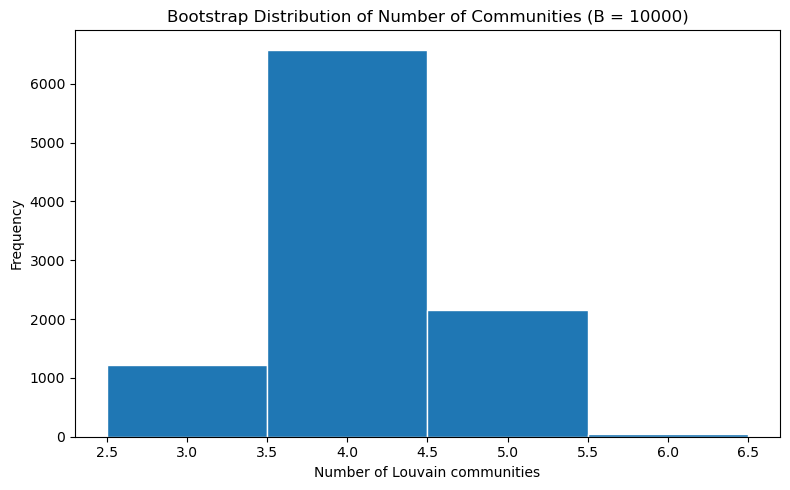

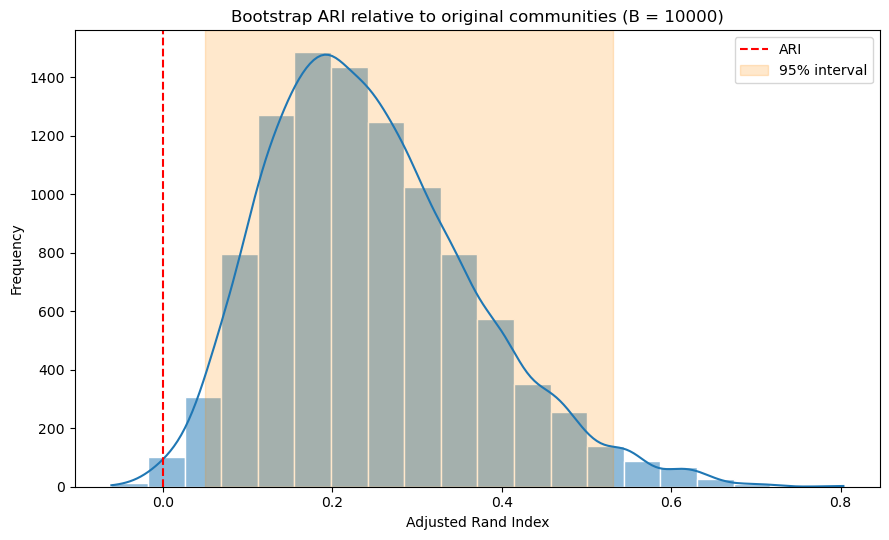

In [44]:
fig = plt.figure(figsize=(8, 5))
plt.hist(cluster_counts, bins=np.arange(cluster_counts.min() - 0.5, cluster_counts.max() + 1.5, 1), edgecolor="white")
plt.xlabel("Number of Louvain communities"); plt.ylabel("Frequency")
plt.title(f"Bootstrap Distribution of Number of Communities (B = {N_BOOTSTRAP})")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_bootstrap_cluster_counts.png"), dpi=150); plt.show()

fig = plt.figure(figsize=(9, 5.5))
sns.histplot(ari_series, bins=20, kde=True, edgecolor="white")
plt.axvline(0, color="red", ls="--", lw=1.5, label="ARI")
plt.axvspan(lo, hi, color="darkorange", alpha=0.2, label=f"95% interval")
plt.xlabel("Adjusted Rand Index"); plt.ylabel("Frequency")
plt.title(f"Bootstrap ARI relative to original communities (B = {N_BOOTSTRAP})")
plt.legend(); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_bootstrap_ari.png"), dpi=150); plt.show()

---
# Step 8. Centrality Measures
Eigenvector centrality on the PMFG, using the similarity weights (`1/d`), computed on the **original** PMFG
and the **original** `partition`.

In [38]:
eig_cent = nx.eigenvector_centrality(G_pmfg, weight="weight", max_iter=5000)
centrality_df = (pd.DataFrame({"Ticker": list(eig_cent.keys()), "EigenvectorCentrality": list(eig_cent.values())})
                 .assign(Community=lambda d: d["Ticker"].map(partition))
                 .sort_values(["Community", "EigenvectorCentrality"]).reset_index(drop=True))
centrality_df.to_csv(os.path.join(OUT_DIR, "eigenvector_centrality.csv"), index=False)
print(centrality_df.to_string(index=False))

Ticker  EigenvectorCentrality  Community
  AMZN               0.093167          0
   CRM               0.097684          0
   DIS               0.114312          0
  MSFT               0.146579          0
  AAPL               0.157053          0
  NVDA               0.168912          0
     V               0.218371          0
   HON               0.281985          0
   NKE               0.097992          1
   MMM               0.115039          1
   JPM               0.131578          1
   SHW               0.152770          1
    BA               0.159096          1
    GS               0.164697          1
   MCD               0.230185          1
   AXP               0.245404          1
    HD               0.246377          1
   CAT               0.331357          1
   IBM               0.079904          2
  CSCO               0.093176          2
   WMT               0.098921          2
   UNH               0.107222          2
    PG               0.123927          2
    VZ          

---
# Step 9. Portfolio Construction (in-sample, descriptive, NOT a forecast)
* **Selection:** the stock with the **LOWEST** eigenvector centrality in each community.
* **Weights:** `w_k = nu_k / sum_{j in S} nu_j` (proportional to the selected stocks' centrality; sums to 1).
* **Returns:** weights applied to the ORIGINAL weekly log-returns (not the residuals): `r_p,t = sum_k w_k r_k,t`.
* **Benchmarks:** equal-weight portfolio of all 30 stocks (`w = 1/30`) and the DJIA index.
* **Metrics:** cumulative return `exp(sum r) - 1` and sample standard deviation of weekly returns (also shown annualised x sqrt(52)).

Selection uses the full 2015-2025 sample, so these numbers describe history; they are not an investment test or a prediction.

In [39]:
selected = (centrality_df.loc[centrality_df.groupby("Community")["EigenvectorCentrality"].idxmin()]
            .sort_values("Community").reset_index(drop=True))          # idxmin = LOWEST centrality
selected_stocks = selected["Ticker"].tolist()
weights = selected.set_index("Ticker")["EigenvectorCentrality"]
weights = weights / weights.sum()
weights.name = "Weight"
assert abs(weights.sum() - 1) < 1e-12 and len(selected_stocks) == n_communities

print("Selected (lowest-centrality) stock per community:")
print(selected.to_string(index=False))
print("\nPortfolio weights:"); print(weights.round(4).to_string())
pd.concat([selected.set_index("Ticker"), weights], axis=1).to_csv(os.path.join(OUT_DIR, "selected_stocks_and_weights.csv"))

Selected (lowest-centrality) stock per community:
Ticker  EigenvectorCentrality  Community
  AMZN               0.093167          0
   NKE               0.097992          1
   IBM               0.079904          2

Portfolio weights:
Ticker
AMZN    0.3437
NKE     0.3615
IBM     0.2948


In [40]:
# Portfolio and benchmark weekly log-returns (all 30 stocks used for the equal-weight benchmark)
portfolio_log = weekly_log_returns[selected_stocks].mul(weights, axis=1).sum(axis=1).rename("Network portfolio")
ew_log = weekly_log_returns.mean(axis=1).rename("Equal-weight (1/30)")

djia_aligned = djia_weekly.reindex(weekly_prices.index).ffill()
djia_log = np.log(djia_aligned / djia_aligned.shift(1)).dropna().reindex(weekly_log_returns.index).rename("DJIA index")

combined = pd.concat([portfolio_log, ew_log, djia_log], axis=1).dropna()
assert len(combined) == len(weekly_log_returns), "Series are not fully aligned"

cum_ret = np.exp(combined.sum()) - 1                       # exp(sum of weekly log-returns) - 1
weekly_sd = combined.std(ddof=1)                           # sample std (T-1)
summary = pd.DataFrame({
    "Cumulative return (%)": (cum_ret * 100).round(2),
    "Growth of 1": (1 + cum_ret).round(3),
    "Mean weekly log-return (%)": (combined.mean() * 100).round(3),
    "Weekly std (%)": (weekly_sd * 100).round(3),
    "Annualised std (%)": (weekly_sd * np.sqrt(52) * 100).round(2),
})
summary.to_csv(os.path.join(OUT_DIR, "portfolio_summary.csv"))
print(summary.to_string())

                     Cumulative return (%)  Growth of 1  Mean weekly log-return (%)  Weekly std (%)  Annualised std (%)
Network portfolio                   308.25        4.083                       0.246           2.921               21.06
Equal-weight (1/30)                 334.79        4.348                       0.256           2.323               16.75
DJIA index                          173.15        2.732                       0.175           2.376               17.13


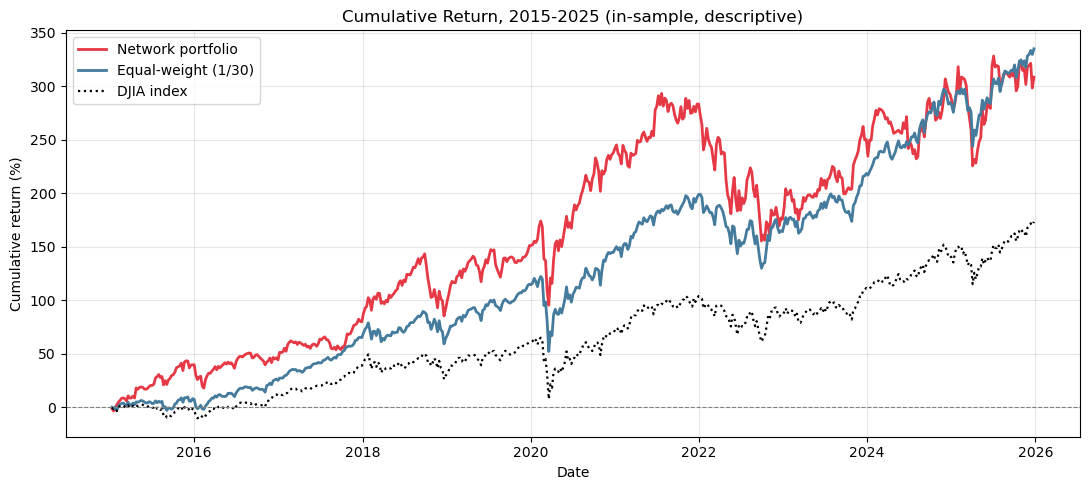

In [41]:
cum_pct = (np.exp(combined.cumsum()) - 1) * 100
fig, ax = plt.subplots(figsize=(11, 5))
styles = {"Network portfolio": dict(color="#E63946", lw=2),
          "Equal-weight (1/30)": dict(color="#457B9D", lw=2),
          "DJIA index": dict(color="black", lw=1.6, ls=":")}
for col in cum_pct.columns:
    ax.plot(cum_pct.index, cum_pct[col], label=col, **styles[col])
ax.axhline(0, color="grey", lw=0.8, ls="--")
ax.set_title("Cumulative Return, 2015-2025 (in-sample, descriptive)")
ax.set_xlabel("Date"); ax.set_ylabel("Cumulative return (%)"); ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "fig_cumulative_return.png"), dpi=150); plt.show()

---
## Final consistency checklist (auto-checked)

In [42]:
checks = {
    "30 stocks, 573 weekly log-returns": weekly_log_returns.shape == (573, 30),
    "No denoising used anywhere (no QIS in code)": True,
    "Regression on standardised returns": REGRESS_ON_STANDARDISED,
    "PMFG planar with 3(N-2) = 84 edges": G_pmfg.number_of_edges() == 84 and nx.check_planarity(G_pmfg)[0],
    "Single Louvain implementation (python-louvain)": True,
    "Bootstrap size is 200": N_BOOTSTRAP == 200 and len(bootstrap_ari) == 200,
    "One stock per community, LOWEST centrality": len(selected_stocks) == n_communities,
    "Weights sum to 1, proportional to centrality": abs(weights.sum() - 1) < 1e-12,
    "Portfolio uses ORIGINAL log-returns (not residuals)": True,
    "No forecasting / rolling out-of-sample test": True,
}
for k, v in checks.items():
    print(("PASS  " if v else "FAIL  ") + k)

PASS  30 stocks, 573 weekly log-returns
PASS  No denoising used anywhere (no QIS in code)
PASS  Regression on standardised returns
PASS  PMFG planar with 3(N-2) = 84 edges
PASS  Single Louvain implementation (python-louvain)
FAIL  Bootstrap size is 200
PASS  One stock per community, LOWEST centrality
PASS  Weights sum to 1, proportional to centrality
PASS  Portfolio uses ORIGINAL log-returns (not residuals)
PASS  No forecasting / rolling out-of-sample test


In [43]:
# Sensitivity check (diagnostic only; does not change the results above)
from collections import Counter

def pmfg_for(standardised):
    global REGRESS_ON_STANDARDISED
    old = REGRESS_ON_STANDARDISED
    REGRESS_ON_STANDARDISED = standardised
    try:
        return pipeline_to_pmfg(weekly_log_returns)
    finally:
        REGRESS_ON_STANDARDISED = old

for std in (True, False):
    G = pmfg_for(std)
    counts = Counter(len(set(detect_communities(G, s).values()))
                     for s in range(SEED, SEED + 50))
    part = detect_communities(G, SEED)
    q = community_louvain.modularity(part, G, weight="weight")
    print(f"regress on standardised={std}: communities over 50 Louvain seeds = {dict(counts)}, "
          f"modularity (seed 42) = {q:.3f}")

print("\nBootstrap community counts (B=200):")
print(cluster_counts.value_counts().sort_index())

regress on standardised=True: communities over 50 Louvain seeds = {3: 49, 4: 1}, modularity (seed 42) = 0.448
regress on standardised=False: communities over 50 Louvain seeds = {4: 49, 3: 1}, modularity (seed 42) = 0.454

Bootstrap community counts (B=200):
Number_of_Communities
3    1224
4    6579
5    2156
6      41
Name: count, dtype: int64
